# Life Satisfaction Prediction using GDP per Capita

## Assignment Note

#### This assignment is not intended to be a full project. It serves as a follow up to reinforce the concepts we have covered in lecture so far. More comprehensive analyses and detailed projects will be introduced as we progress further into the course.

---

👀 Learning Objectives

- Load and visualize real-world data.

- Train and compare regression models using Scikit-Learn.

- Interpret model outputs and discuss generalization.

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

## Part 1: Data Exploration and Visualization

### Q1 (5 marks) Load the dataset lifesat.csv and display the first 5 rows.

In [2]:
df = pd.read_csv("lifesat.csv")
df.head()

,Country,GDP per capita (USD),Life satisfaction
0,Russia,26456.387938,5.8
1,Greece,27287.083401,5.4
2,Turkey,28384.987785,5.5
3,Latvia,29932.493910,5.9
4,Hungary,31007.768407,5.6


### Q2 (5 marks) Print basic info and summary statistics.

In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country               27 non-null     object 
 1   GDP per capita (USD)  27 non-null     float64
 2   Life satisfaction     27 non-null     float64
dtypes: float64(2), object(1)
memory usage: 780.0+ bytes


,GDP per capita (USD),Life satisfaction
count,27.000000,27.000000
mean,41564.521771,6.566667
std,9631.452319,0.765607
min,26456.387938,5.400000
25%,33938.289305,5.900000
50%,41627.129269,6.800000
75%,49690.580269,7.300000
max,60235.728492,7.600000


### Q3 (10 marks) Display a scatter plot for GDP per capita vs Life Satisfaction . Add labels, title, and discuss the observed relationship.

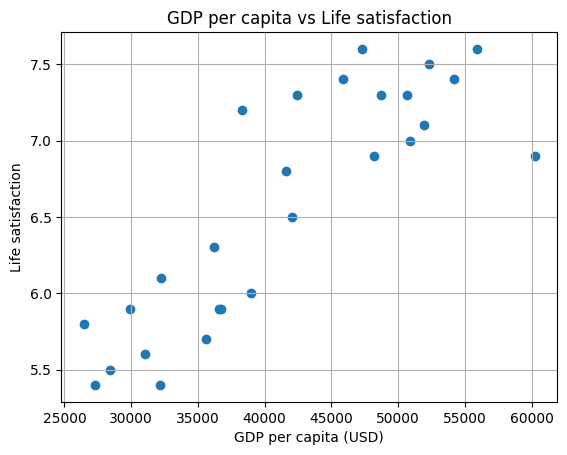

In [4]:
plt.scatter(df["GDP per capita (USD)"], df["Life satisfaction"])
plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life satisfaction")
plt.title("GDP per capita vs Life satisfaction")
plt.grid(True)
plt.show()

### Discussion: the plot shows a clear positive relationship. Countries with higher GDP per capita tend to report higher life satisfaction. The trend looks roughly linear, though with some spread and a few outliers. The gain also seems to flatten at high GDP, and correlation doesn't mean causation, since other factors like health and social support matter too.

---

# Part 2: Linear Regression Model 

### Q4 (5 marks) Extract input (X) and target (y). Print their shapes.

In [5]:
X = df[["GDP per capita (USD)"]].values   # double brackets keep it 2D
y = df["Life satisfaction"].values
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (27, 1)
y shape: (27,)


### Q5 (10 marks) Train a Linear Regression model & Display coefficient and intercept.

In [6]:
lin_model = LinearRegression()
lin_model.fit(X, y)
print("Coefficient:", lin_model.coef_[0])
print("Intercept:", lin_model.intercept_)

Coefficient: 6.778899694341226e-05
Intercept: 3.7490494273769075


### Q6 (10 marks) Plot the predicted regression line from the model along with a scatter plot of the data.

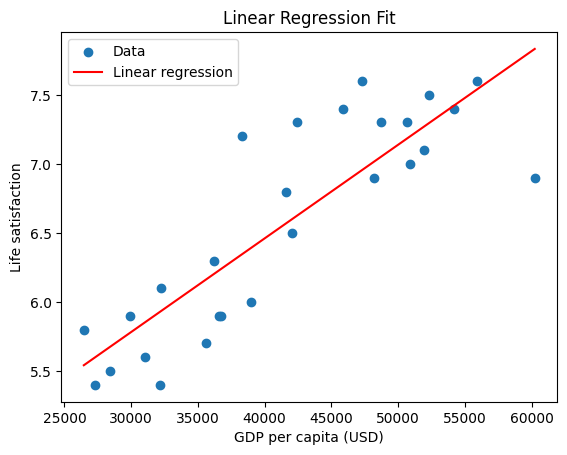

In [7]:
plt.scatter(X, y, label="Data")
plt.plot(X, lin_model.predict(X), color="red", label="Linear regression")
plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life satisfaction")
plt.title("Linear Regression Fit")
plt.legend()
plt.show()

### Q7 (5 marks) Predict Life Satisfaction for GDP = 37,655.2 USD. Comment on result.

In [8]:
X_new = [[37655.2]]
lin_pred = lin_model.predict(X_new)
print("Linear Regression prediction:", lin_pred[0])

Linear Regression prediction: 6.3016576650804845


#### Comment: the prediction is around 6.3. That is plausible and sits in the middle of the data, and the model gives one smooth estimate based on the overall trend.

# Part 3: K-Nearest Neighbors Regression

## Q8 (5 marks) Train a KNeighborsRegressor (n_neighbors=3).

In [9]:
knn_model = KNeighborsRegressor(n_neighbors=3)
knn_model.fit(X, y)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


# Q9 (10 marks)

In [10]:
knn_pred = knn_model.predict(X_new)
print("KNN (k=3) prediction:", knn_pred[0])
print("Linear Regression prediction:", lin_pred[0])
print("Difference:", abs(knn_pred[0] - lin_pred[0]))

KNN (k=3) prediction: 6.333333333333333
Linear Regression prediction: 6.3016576650804845
Difference: 0.03167566825284851


### Comment: the two predictions should be close. Linear regression uses a global straight-line fit, while KNN averages the 3 countries with the closest GDP, so it follows local patterns and is more sensitive to individual data points.

## Q10 (10 marks)

n_neighbors=1: 7.200
n_neighbors=3: 6.333
n_neighbors=5: 6.260
n_neighbors=10: 6.370


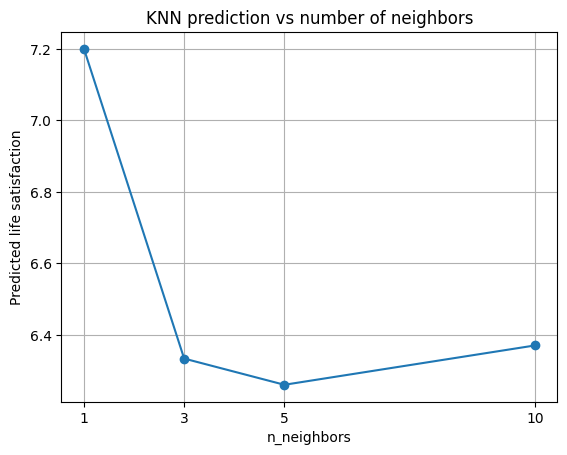

In [11]:
n_list = [1, 3, 5, 10]
pred_list = []

for n in n_list:
    knn = KNeighborsRegressor(n_neighbors=n)
    knn.fit(X, y)
    p = knn.predict(X_new)[0]
    pred_list.append(p)
    print(f"n_neighbors={n}: {p:.3f}")

# Plot n vs pred_list
plt.plot(n_list, pred_list, marker="o")
plt.xlabel("n_neighbors")
plt.ylabel("Predicted life satisfaction")
plt.title("KNN prediction vs number of neighbors")
plt.xticks(n_list)
plt.grid(True)
plt.show()

### Comment: with small k (like 1), the prediction depends on a single country, so it's noisy and prone to overfitting. As k grows, predictions get smoother and more stable but can underfit. This is the bias-variance tradeoff.